In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("cardekho.csv")

In [3]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


In [4]:
df.shape

(8128, 12)

In [5]:
df.isnull().sum()

name                    0
year                    0
selling_price           0
km_driven               0
fuel                    0
seller_type             0
transmission            0
owner                   0
mileage(km/ltr/kg)    221
engine                221
max_power             215
seats                 221
dtype: int64

In [6]:
df.dtypes

name                   object
year                    int64
selling_price           int64
km_driven               int64
fuel                   object
seller_type            object
transmission           object
owner                  object
mileage(km/ltr/kg)    float64
engine                float64
max_power              object
seats                 float64
dtype: object

In [7]:
num_cols = df.select_dtypes(include='number').columns

df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

In [8]:
cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [9]:
df.isnull().sum()

name                  0
year                  0
selling_price         0
km_driven             0
fuel                  0
seller_type           0
transmission          0
owner                 0
mileage(km/ltr/kg)    0
engine                0
max_power             0
seats                 0
dtype: int64

In [10]:
cat_cols

Index(['name', 'fuel', 'seller_type', 'transmission', 'owner', 'max_power'], dtype='object')

In [11]:
encoder= LabelEncoder()

In [12]:
for column in cat_cols:
    df[column]= encoder.fit_transform(df[column])

In [13]:
X= df.drop("selling_price", axis=1)
y= df["selling_price"]

In [14]:
X_train, X_test, y_train, y_test= train_test_split(X, y, test_size=0.25, random_state=42)

In [15]:
lr= LinearRegression()

In [16]:
lr.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [17]:
y_pred_lr= lr.predict(X_test)

In [18]:
print("MAE :", mean_absolute_error(y_test,y_pred_lr))
print("MSE :", mean_squared_error(y_test,y_pred_lr))
print("RMSE :", mean_squared_error(y_test,y_pred_lr) ** 0.5)
print("R2 score :", r2_score(y_test,y_pred_lr))

MAE : 295024.7230661528
MSE : 252961252237.08823
RMSE : 502952.5347754878
R2 score : 0.5941729041599002


In [19]:
dt= DecisionTreeRegressor(criterion='squared_error', max_depth=5, min_samples_split=2, min_samples_leaf=1, random_state=42)

In [20]:
dt.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [21]:
y_pred_dt = dt.predict(X_test)

In [22]:
print("MAE :", mean_absolute_error(y_test,y_pred_dt))
print("MSE :", mean_squared_error(y_test,y_pred_dt))
print("RMSE :", mean_squared_error(y_test,y_pred_dt) ** 0.5)
print("R2 score :", r2_score(y_test,y_pred_dt))

MAE : 134135.57153392266
MSE : 57575870088.12392
RMSE : 239949.72408428378
R2 score : 0.9076307223272656


In [23]:
rf= RandomForestRegressor(n_estimators=100,max_depth=5)

In [24]:
rf.fit(X_train,y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [25]:
y_pred_rf = rf.predict(X_test)

In [26]:
print("MAE :", mean_absolute_error(y_test,y_pred_rf))
print("MSE :", mean_squared_error(y_test,y_pred_rf))
print("RMSE :", mean_squared_error(y_test,y_pred_rf) ** 0.5)
print("R2 score :", r2_score(y_test,y_pred_rf))

MAE : 120767.584107472
MSE : 42623303357.593445
RMSE : 206454.11925557078
R2 score : 0.9316192054563699


In [27]:
grad = GradientBoostingRegressor(
    n_estimators= 150,
    learning_rate=0.5,
    max_depth= 3,
    random_state=42
)

In [28]:
grad.fit(X_train,y_train)

,loss,'squared_error'
,learning_rate,0.5
,n_estimators,150
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [29]:
y_pred_grad= grad.predict(X_test)

In [30]:
print("MAE :", mean_absolute_error(y_test,y_pred_grad))
print("MSE :", mean_squared_error(y_test,y_pred_grad))
print("RMSE :", mean_squared_error(y_test,y_pred_grad) ** 0.5)
print("R2 score :", r2_score(y_test,y_pred_grad))

MAE : 77502.92211412331
MSE : 24850321330.555317
RMSE : 157639.84689968242
R2 score : 0.9601324959965788


<!-- comparision -->

Comparision

In [31]:
comparision = pd.DataFrame({
    'Model': ["Linear_reg", "Decision_Tree", "Random_forest", "Grad_Boosting"],
    'MAE': [mean_absolute_error(y_test,y_pred_lr), mean_absolute_error(y_test,y_pred_dt), mean_absolute_error(y_test,y_pred_rf), mean_absolute_error(y_test,y_pred_grad)],
    'MSE': [mean_squared_error(y_test,y_pred_lr), mean_squared_error(y_test,y_pred_dt), mean_squared_error(y_test,y_pred_rf), mean_squared_error(y_test,y_pred_grad)],
    'RMSE': [(mean_squared_error(y_test,y_pred_lr) ** 0.5), (mean_squared_error(y_test,y_pred_dt) ** 0.5), (mean_squared_error(y_test,y_pred_rf) ** 0.5), (mean_squared_error(y_test,y_pred_grad) ** 0.5)],
    'R2_score': [r2_score(y_test,y_pred_lr), r2_score(y_test,y_pred_dt), r2_score(y_test,y_pred_rf), r2_score(y_test,y_pred_grad)]
})

In [32]:
comparision

,Model,MAE,MSE,RMSE,R2_score
0,Linear_reg,295024.723066,2.529613e+11,502952.534775,0.594173
1,Decision_Tree,134135.571534,5.757587e+10,239949.724084,0.907631
2,Random_forest,120767.584107,4.262330e+10,206454.119256,0.931619
3,Grad_Boosting,77502.922114,2.485032e+10,157639.846900,0.960132


In [33]:
import seaborn as sns

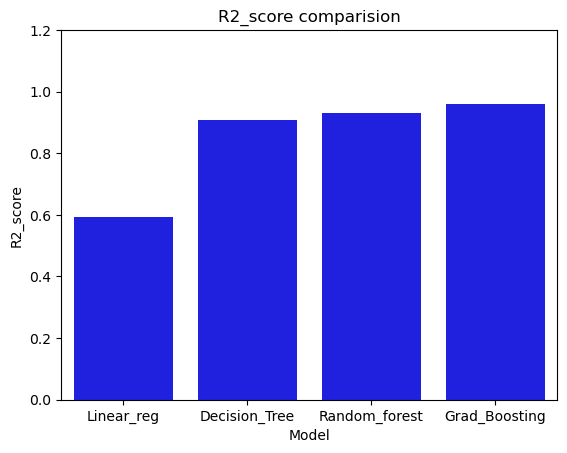

In [34]:
sns.barplot(x="Model", y="R2_score", data=comparision,color="blue")
plt.title("R2_score comparision")
plt.ylim(0,1.2)
plt.show()

In [35]:
import joblib

In [36]:
joblib.dump(grad, "best_model.pkl")

['best_model.pkl']

In [37]:
joblib.dump(encoder, "label_encoder.pkl")

['label_encoder.pkl']

In [38]:
joblib.dump(X.columns.tolist(), "feature_columns.pkl"  )

['feature_columns.pkl']

In [39]:
import os
os.listdir()

['.ipynb_checkpoints',
 'best_model.pkl',
 'cardekho.csv',
 'CarDekho_price_prediction.ipynb',
 'feature_columns.pkl',
 'label_encoder.pkl']